# ISCAS 2027 — Linear-tag LCU: resources, noise, interference and key reuse

This notebook contains the four selected experiments (2, 3, 4 and 5), their
theoretical models, adjustable parameters, measurements and interpretation.
The shared implementations live in `linear_tag.py` and `experiments.py`.
After changing `CONFIG`, select **Restart Kernel and Run All**.

The default campaign is exploratory, not a final publication-scale statistical
study. Saved outputs are actual executions. No experiment establishes quantum
advantage, IND-CPA security or a production-ready cipher.

## 0. Explicit model definitions

### Model A — Ideal keyed linear-tag channel

Let $n$ be the input length, $1\le s\le n$ the tag width and $\nu$ the number of
blocks. All vector operations are over $\mathbb F_2$.
$X$ is uniform on $\mathbb F_2^n$. Key generation independently samples
$B_j\in\mathbb F_2^{s\times n}$ with independent uniform entries. Public
parameters are $(n,s,\nu)$; matrices are secret. Each fresh-key challenge
releases **one execution per block**.

The registers are $I$ ($n$ qubits), $R$ ($s$ qubits), and $S$ ($n$ qubits).
Define
$$\mathcal T_B|t\rangle|r\rangle=|t\rangle|r\oplus Bt\rangle,\qquad
\mathrm{SELECT}_{\oplus}|t\rangle|x\rangle=|t\rangle|x\oplus t\rangle.$$
Starting from $|0^n\rangle_I|0^s\rangle_R|x\rangle_S$, apply
$H_I,\mathcal T_B,\mathrm{SELECT}_{\oplus},H_I$:
$$|\Psi_{B,x}\rangle=2^{-n}\sum_{i,t}(-1)^{i\cdot t}
|i\rangle|Bt\rangle|x\oplus t\rangle.$$
Computational-basis measurement releases $Z=(I,R,Y)$ with
$$P(I=i,R=r,Y=y\mid x,B)=2^{-2n}\mathbf1\{r=B(x\oplus y)\}.$$
An exact classical implementation samples independent uniform $T,I$ and returns
$(I,BT,x\oplus T)$. This is the reference distribution, not an approximation.

**Authorized decoder.** Compute $c_j=R_j\oplus B_jY_j$ and stack the equations:
$$A=\begin{bmatrix}B_1\\\vdots\\B_\nu\end{bmatrix},\qquad
c=\begin{bmatrix}c_1\\\vdots\\c_\nu\end{bmatrix},\qquad Ax=c.$$
Return the unique solution only if the system is consistent and has rank $n$;
otherwise report failure. Checking consistency extends the ideal decoder to
noisy data without pretending to correct errors.

**Resource model.** Blocks execute sequentially, reusing registers:
$$Q=2n+s,\quad |k|=\nu sn,\quad
N_{\rm CX}=\nu n+\sum_j\|B_j\|_0,\quad
\mathbb E[N_{\rm CX}]=\nu(n+sn/2).$$
With $m=\nu s\ge n$, the exact rank failure probability is
$$\epsilon_{\rm rank}(n,m)=1-\prod_{i=0}^{n-1}(1-2^{i-m});$$
it equals 1 for $m<n$. No rank-deficient keys are discarded or resampled.

### Model B — Noisy implementation of the same linear-tag circuit

Compile the circuit to `h,x,s,sdg,z,cx`. Apply independent depolarizing channels
after the corresponding one- and two-qubit gates:
$$\mathcal D_p^{(d)}(\rho)=(1-p)\rho+pI_d/d,\qquad d=2\ \text{or}\ 4.$$
For a gate embedded in a larger system, this denotes the local channel on
its operand qubits. `p1` and `p2` are Aer depolarizing parameters, not directly
average gate infidelities. Each measured bit is independently flipped with
probability $p_{\rm meas}$:
$$M=\begin{pmatrix}1-p_{\rm meas}&p_{\rm meas}\\
p_{\rm meas}&1-p_{\rm meas}\end{pmatrix}.$$
This reproduces the composition used in the 2026 code, adapted to the actual
Clifford gate basis. Defaults are $(p_1,p_2,p_{\rm meas})=(0.001,0.005,0.02)$.
Setting all three to zero recovers Model A. `gates`, `readout` and `combined`
isolate noise sources; `scale` multiplies the relevant parameters.

The decoder records **correct**, **declared failure**, and **wrong unique
solution** separately. Under readout-only noise,
$$\widetilde c_j=B_jx\oplus e_{R,j}\oplus B_je_{Y,j}.$$
Extra equations ensure ideal rank, but do not by themselves implement error
correction. Idle decoherence, leakage, crosstalk, reset errors and device-specific
calibrations are outside this synthetic model.

### Model C — Two-label permutation LCU with controlled interference

This is a separate public circuit family, not the secret-matrix linear-tag.
There is one index qubit, one rotation qubit and $n$ system qubits. For $t=0,1$:
$$R_t=\begin{pmatrix}w_t&\sqrt{1-w_t^2}\\
\sqrt{1-w_t^2}&-w_t\end{pmatrix}
=R_y(2\arccos w_t)Z,\qquad -1\le w_t\le1.$$
Prepare the index with $H$, apply controlled $R_t\otimes U_t$, add phase
$e^{i\phi t}$, and finish with index $H$. With
$a_{0,t}=w_t$ and $a_{1,t}=\sqrt{1-w_t^2}$:
$$P(i,b,y\mid x)=\frac14\left|
\sum_{t:\pi_t(x)=y}(-1)^{it}e^{i\phi t}a_{b,t}\right|^2.$$
The **disjoint** family has $\pi_0(x)=x$ and
$\pi_1(x)=x\oplus e_{\rm target}$. The **overlap** family uses
$\pi_1(x)=\mathrm{CNOT}_{control,target}(x)$, so branches collide when the
input control bit is zero.

Before the final index $H$, apply
$$\mathcal E_d(\rho)=(1-d/2)\rho+(d/2)Z_I\rho Z_I,\qquad 0\le d\le1.$$
$d=0$ is coherent and $d=1$ is fully dephased. This control channel is distinct
from Model B's gate/readout noise. We compute exact distributions, their total
variation distance, and optimal recovery for uniform inputs:
$$p_{\rm guess}=2^{-n}\sum_{i,b,y}\max_x P(i,b,y\mid x).$$
Weights, phases and permutations are public, not hidden attack inputs.

### Model D — Repeated-execution attack

For each block, repeat Model A $q$ times with **the same matrix and the same
unknown input**. Fresh masks are still sampled each time. The attacker receives
only transcripts. Differences cancel the unknown input:
$$R_a\oplus R_0=B_j(Y_a\oplus Y_0),\qquad D_YB_j^\top=D_R.$$
If $D_Y$ has rank $n$, the attacker reconstructs $B_j$. After uniquely recovering
all block matrices, it applies the authorized decoder to their first transcripts.
This concrete attack abstains if it cannot identify all matrices; it is not
claimed to be an optimal attack. The `fresh` control regenerates the matrix at
every execution. Model D is ideal and explicitly outside the fresh-key theorem;
it does not cover noisy observations or different messages under one key.

### Implementation and bit order

Arrays are little-endian: entry `q` has weight $2^q$. Quantum and classical
indices are `I[0:n], R[n:n+s], Y[n+s:2*n+s]`. Qiskit prints bitstrings in the
opposite order; `parse_memory` reverses them and preserves the classical
register interpretation after routing. The next cells expose the actual
shared model implementations so their definitions remain visible here without
maintaining a second, potentially inconsistent copy.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import importlib.metadata as metadata
import json
import math
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit.quantum_info import Statevector

ROOT = Path.cwd()
if not (ROOT / "linear_tag.py").exists():
    ROOT = ROOT / "iscas2027_experiments"
if not (ROOT / "linear_tag.py").exists():
    raise FileNotFoundError("Open the notebook in iscas2027_experiments or its parent directory.")
sys.path.insert(0, str(ROOT.resolve()))

from linear_tag import (
    binary, bits_int, int_bits, linear_tag_circuit, compile_circuit,
    run_memory, parse_memory, decode,
    rank_failure_exact, wilson,
)
from experiments import (
    resource_experiment, noise_experiment, noise_summary,
    interference_experiment, reuse_experiment,
)

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 180, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": .2,
    "font.size": 10, "figure.constrained_layout.use": True,
})
pd.set_option("display.max_columns", 24)
pd.set_option("display.precision", 5)

In [2]:
# Display the exact shared implementations used below, rather than duplicating them.
import inspect
from IPython.display import Code, Markdown
from linear_tag import (
    linear_tag_circuit, sample_transcript, decode, noise_model,
    permutation_lcu_prefix, permutation_lcu_probabilities, recover_reused_matrix,
)

for model_name, functions in [
    ("Model A: circuit, exact sampler and decoder",
     [linear_tag_circuit, sample_transcript, decode]),
    ("Model B: gate and readout noise", [noise_model]),
    ("Model C: permutation LCU and index dephasing",
     [permutation_lcu_prefix, permutation_lcu_probabilities]),
    ("Model D: transcript-only matrix recovery", [recover_reused_matrix]),
]:
    display(Markdown(f"### {model_name}"))
    for function in functions:
        display(Code(inspect.getsource(function), language="python"))

### Model A: circuit, exact sampler and decoder

def linear_tag_circuit(B, x, measure=True):
    B, x = binary(B, 2), binary(x, 1)
    s, n = B.shape
    if not 1 <= s <= n or len(x) != n:
        raise ValueError("Require 1 <= s <= n and len(x) == n.")
    width = 2 * n + s
    qc = QuantumCircuit(width, width if measure else 0, name=f"linear_tag_n{n}_s{s}")
    for q in np.flatnonzero(x):
        qc.x(n + s + int(q))
    qc.h(range(n))
    qc.barrier()
    for row, col in np.argwhere(B):
        qc.cx(int(col), n + int(row))
    qc.barrier()
    for q in range(n):
        qc.cx(q, n + s + q)
    qc.barrier()
    qc.h(range(n))
    if measure:
        qc.measure(range(width), range(width))
    return qc

def sample_transcript(B, x, rng):
    """Exact ideal sampler; returns the complete (I, R, Y) transcript."""
    B, x = binary(B, 2), binary(x, 1)
    if B.shape[1] != len(x):
        raise ValueError("B and x dimensions differ.")
    t = rng.integers(0, 2, len(x), dtype=np.uint8)
    i = rng.integers(0, 2, len(x), dtype=np.uint8)
    return i, (B @ t) % 2, x ^ t

def decode(matrices, transcripts):
    if not len(matrices) or len(matrices) != len(transcripts):
        raise ValueError("Need one transcript per keyed block.")
    blocks, values = [], []
    for B, (_, r, y) in zip(matrices, transcripts):
        B, r, y = binary(B, 2), binary(r, 1), binary(y, 1)
        if B.shape != (len(r), len(y)):
            raise ValueError("Transcript and key dimensions differ.")
        blocks.append(B)
        values.append(r ^ ((B @ y) % 2))
    return solve_gf2(np.vstack(blocks), np.concatenate(values))

### Model B: gate and readout noise

...

### Model C: permutation LCU and index dephasing

def permutation_lcu_prefix(n, x, family, phase, weights, control=0, target=1):
    """K=2 all-outcomes circuit: index, rotation, n system qubits; before final H."""
    if n < 2 or not 0 <= control < n or not 0 <= target < n or control == target:
        raise ValueError("Need n >= 2 and distinct valid control/target.")
    if family not in ("disjoint", "overlap"):
        raise ValueError("Unknown permutation family.")
    if len(weights) != 2 or not all(np.isfinite(w) and abs(w) <= 1 for w in weights):
        raise ValueError("Need two real weights in [-1, 1].")
    if not np.isfinite(phase):
        raise ValueError("Phase must be finite.")
    qc = QuantumCircuit(n + 2)
    for q in np.flatnonzero(int_bits(x, n)):
        qc.x(2 + int(q))
    qc.h(0)
    for t, w in enumerate(weights):
        if t == 0:
            qc.x(0)
        qc.cz(0, 1)
        qc.cry(2 * math.acos(w), 0, 1)  # R_t = Ry(2 acos w_t) Z.
        if t == 0:
            qc.x(0)
    if family == "disjoint":
        qc.cx(0, 2 + target)
    else:
        qc.ccx(0, 2 + control, 2 + target)
    qc.p(phase, 0)
    return qc

def permutation_lcu_probabilities(n, x, family, phase=0, dephase=0,
                                  weights=(1.0, 1.0), control=0, target=1):
    if not 0 <= dephase <= 1:
        raise ValueError("dephase must be in [0, 1].")
    # shortcut: exhaustive density matrices, use a different simulator beyond six system qubits.
    if n > 6:
        raise ValueError("This exhaustive interference benchmark supports n <= 6.")
    qc = permutation_lcu_prefix(n, x, family, phase, weights, control, target)
    rho = DensityMatrix.from_instruction(qc)
    channel = Kraus([
        math.sqrt(1 - dephase / 2) * np.eye(2),
        math.sqrt(dephase / 2) * np.diag([1, -1]),
    ])
    rho = rho.evolve(channel, qargs=[0])
    final = QuantumCircuit(n + 2)
    final.h(0)
    p = np.asarray(rho.evolve(final).probabilities(), dtype=float)
    if np.min(p) < -1e-10 or not np.isclose(p.sum(), 1):
        raise ArithmeticError("Invalid circuit distribution.")
    p = np.maximum(p, 0)
    return p / p.sum()

### Model D: transcript-only matrix recovery

def recover_reused_matrix(transcripts):
    """Ciphertext-only attack for repeated executions with the SAME B and SAME x."""
    if not transcripts:
        raise ValueError("Need at least one transcript.")
    _, r0, y0 = transcripts[0]
    dy = np.array([y ^ y0 for _, _, y in transcripts[1:]], dtype=np.uint8)
    dr = np.array([r ^ r0 for _, r, _ in transcripts[1:]], dtype=np.uint8)
    dy, dr = dy.reshape(-1, len(y0)), dr.reshape(-1, len(r0))
    solution, rank, status = solve_gf2(dy, dr)
    return (None if solution is None else solution.T), rank, status

## 1. Adjustable parameters and reproducibility

All scientific campaign parameters are centralized in `CONFIG`. No module edits
are needed to change dimensions, tag widths, margins, noise, topology, phases or
sample counts. Experiment 2 filters `tag_widths` to $1\le s\le n$ for each $n$;
Experiment 3 requires all specified widths to be valid.

- `seed`: regenerates keys, inputs and samples reproducibly.
- `delta`: requested rank margin; $\nu=\lceil(n+\Delta)/s\rceil$. The actual
  margin $\nu s-n$ may be larger because of rounding.
- `resource.key_trials`: independent key sets used for compiled costs;
  `resource.rank_trials`: independent matrices for the rank-failure estimate.
- `noise.trials`: independent challenges, with **one shot per keyed block**.
- `noise_base`: the 2026 model's depolarizing and symmetric readout parameters.
  The old notebooks also used `p2=0.008`; this can be selected here.
- `all`, `line`, `grid`: bidirectional connectivity. A rectangular grid may add
  unused physical sites; both logical and physical widths are recorded.
- `optimization_level`: transpiler level (0–3), with an identity initial layout,
  a fixed Clifford basis and a recorded transpiler seed.
- `dephasings`: 0 means coherent; 1 means fully dephased before the final index H.
- `reuse.nu`: independent block count for the reuse experiment.

For more precise studies, first increase `noise.trials` to 256/1024,
`resource.key_trials` to 32, `resource.rank_trials` to 10000 and `reuse.trials`
to 2048. Test $n=32,64$ separately for resources before expanding every grid.
Routing becomes expensive. Experiment 4 enumerates every input and uses density
matrices: the implementation deliberately limits it to $n\le6$.

Every run creates a new timestamped output directory. Existing runs are preserved.

In [3]:
CONFIG = {
    "seed": 2027,
    "confidence": 0.95,
    "optimization_level": 1,
    "noise_base": {"p1": 1e-3, "p2": 5e-3, "p_meas": 2e-2},
    "demo": {
        "B": [[1, 0, 1], [0, 1, 1]],
        "x": 5,
        "shots": 4096,
        "topology": "all",
        "noise_scale": 1.0,
    },
    "resource": {
        "ns": [4, 8, 16], "tag_widths": [2, 4, 8, 16], "delta": 4,
        "key_trials": 4, "rank_trials": 512, "topologies": ["all", "line", "grid"],
    },
    "noise": {
        "n": 6, "tag_widths": [2, 3, 6], "delta": 2, "trials": 32,
        "topologies": ["all", "line"], "scales": [0.0, 1.0, 2.0],
        "modes": ["combined", "gates", "readout"],
    },
    "interference": {
        "n": 2, "phases": np.linspace(0, 2*np.pi, 17).tolist(),
        "dephasings": [0.0, 0.5, 1.0], "weights": [1.0, 1.0],
        "control": 0, "target": 1,
    },
    "reuse": {
        "n": 8, "s": 2, "nu": 6,
        "repetitions": [1, 4, 8, 9, 12, 16, 24], "trials": 256,
    },
}

RUN_DIR = ROOT / "results" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
RUN_DIR.mkdir(parents=True, exist_ok=False)
versions = {name: metadata.version(name)
            for name in ("qiskit", "qiskit-aer", "numpy", "pandas", "matplotlib")}
(RUN_DIR / "config.json").write_text(
    json.dumps({"parameters": CONFIG, "versions": versions, "python": sys.version},
               indent=2, ensure_ascii=False), encoding="utf-8",
)

def save_table(table, name):
    table.to_csv(RUN_DIR / f"{name}.csv", index=False)

def save_figure(fig, name):
    fig.savefig(RUN_DIR / f"{name}.png")
    fig.savefig(RUN_DIR / f"{name}.pdf")
    plt.show()

display(pd.Series(versions, name="version"))
print("Output directory for this run:", RUN_DIR)

qiskit         2.1.1
qiskit-aer    0.17.1
numpy          2.1.3
pandas         2.2.3
matplotlib    3.10.0
Name: version, dtype: object

Output directory for this run: C:\Users\marco\Desktop\Università\quantum\iscas2027_quantum_crypto\iscas2027_experiments\results\20261020T140200_568104Z


## 2. Inspect and validate the linear-tag block

**Question:** does the implementation reproduce the paper's distribution, and
how does noise change it?

We compare the exact formula, an ideal statevector, ideal Aer samples and noisy
Aer samples. Statevectors are used only for this small validation, not for the
full campaign. The demo is limited to 16 total qubits.

These visualization shots repeat a fixed key to estimate its distribution.
**They are not a fresh-key security challenge.** With the default $s<n$, one
block is insufficient to decode the entire input uniquely. Full-protocol recovery
is measured in Experiment 3.

In [4]:
demo = CONFIG["demo"]
B = binary(demo["B"], 2)
s, n = B.shape
x = int_bits(demo["x"], n)
if 2*n+s > 16:
    raise ValueError("Reduce the demo size: exhaustive statevector validation is limited to 16 qubits.")
qc = linear_tag_circuit(B, x)
print("B =\n", B, "\nx (little-endian) =", x)
print(qc.draw(output="text", fold=110))

B =
 [[1 0 1]
 [0 1 1]] 
x (little-endian) = [1 0 1]
     ┌───┐ ░                      ░                 ░ ┌───┐            ┌─┐      
q_0: ┤ H ├─░───■──────────────────░───■─────────────░─┤ H ├────────────┤M├──────
     ├───┤ ░   │                  ░   │             ░ ├───┤            └╥┘┌─┐   
q_1: ┤ H ├─░───┼────■─────────────░───┼────■────────░─┤ H ├─────────────╫─┤M├───
     ├───┤ ░   │    │             ░   │    │        ░ ├───┤             ║ └╥┘┌─┐
q_2: ┤ H ├─░───┼────┼────■────■───░───┼────┼────■───░─┤ H ├─────────────╫──╫─┤M├
     └───┘ ░ ┌─┴─┐  │  ┌─┴─┐  │   ░   │    │    │   ░ └┬─┬┘             ║  ║ └╥┘
q_3: ──────░─┤ X ├──┼──┤ X ├──┼───░───┼────┼────┼───░──┤M├──────────────╫──╫──╫─
           ░ └───┘┌─┴─┐└───┘┌─┴─┐ ░   │    │    │   ░  └╥┘ ┌─┐          ║  ║  ║ 
q_4: ──────░──────┤ X ├─────┤ X ├─░───┼────┼────┼───░───╫──┤M├──────────╫──╫──╫─
     ┌───┐ ░      └───┘     └───┘ ░ ┌─┴─┐  │    │   ░   ║  └╥┘┌─┐       ║  ║  ║ 
q_5: ┤ X ├─░──────────────────────░─┤ X ├──┼────┼───░───

max_abs_error_statevector_vs_formula    1.38778e-17
TV_ideal_sample_vs_formula              5.71289e-02
TV_noisy_sample_vs_formula              1.19873e-01
syndrome_violation_ideal                0.00000e+00
syndrome_violation_noisy                1.14990e-01
dtype: float64

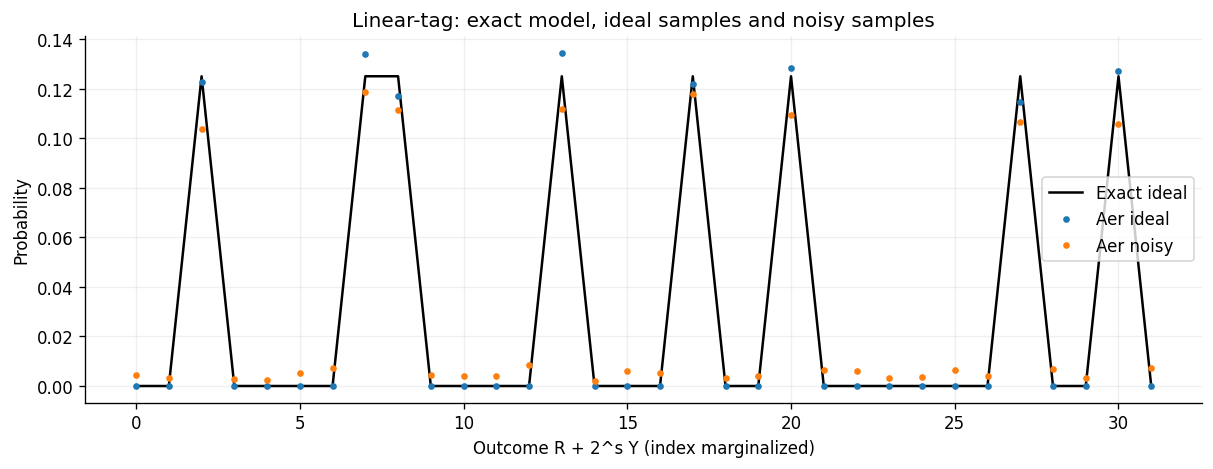

In [5]:
width = 2*n+s
theory = np.zeros(2**width)
for t in range(2**n):
    r = bits_int(B @ int_bits(t, n) % 2)
    for i in range(2**n):
        theory[i + (r << n) + ((demo["x"] ^ t) << (n+s))] = 2.**(-2*n)
state = Statevector.from_instruction(linear_tag_circuit(B, x, measure=False)).probabilities()
max_error = np.max(np.abs(theory-state))
assert max_error < 1e-12

compiled = compile_circuit(qc, demo["topology"], CONFIG["seed"], CONFIG["optimization_level"])
ideal_memory = run_memory([compiled], demo["shots"], CONFIG["seed"])[0]
scaled_noise = {k: v*demo["noise_scale"] for k, v in CONFIG["noise_base"].items()}
noisy_memory = run_memory([compiled], demo["shots"], CONFIG["seed"], **scaled_noise)[0]
ideal_hist = np.bincount([int(m.replace(" ", ""), 2) for m in ideal_memory], minlength=2**width)
noisy_hist = np.bincount([int(m.replace(" ", ""), 2) for m in noisy_memory], minlength=2**width)
ideal_hist = ideal_hist/demo["shots"]
noisy_hist = noisy_hist/demo["shots"]
demo_table = pd.DataFrame({
    "outcome": np.arange(2**width), "exact": theory,
    "ideal_sample": ideal_hist, "noisy_sample": noisy_hist,
})
save_table(demo_table, "linear_tag_distribution")

def violation_rate(memories):
    bad = 0
    for memory in memories:
        _, r, y = parse_memory(memory, n, s)
        bad += int(np.any(r ^ (B @ (x ^ y) % 2)))
    return bad/len(memories)

diagnostics = pd.Series({
    "max_abs_error_statevector_vs_formula": max_error,
    "TV_ideal_sample_vs_formula": np.abs(ideal_hist-theory).sum()/2,
    "TV_noisy_sample_vs_formula": np.abs(noisy_hist-theory).sum()/2,
    "syndrome_violation_ideal": violation_rate(ideal_memory),
    "syndrome_violation_noisy": violation_rate(noisy_memory),
})
assert diagnostics["syndrome_violation_ideal"] == 0
display(diagnostics)
save_table(diagnostics.rename_axis("metric").reset_index(name="value"), "linear_tag_checks")

# Marginalize the index for readability; the CSV retains the full distribution.
marginal = demo_table.assign(ry=demo_table.outcome // 2**n).groupby("ry").sum(numeric_only=True)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(marginal.index, marginal.exact, "-", color="black", label="Exact ideal")
ax.plot(marginal.index, marginal.ideal_sample, ".", label="Aer ideal")
ax.plot(marginal.index, marginal.noisy_sample, ".", label="Aer noisy")
ax.set(xlabel="Outcome R + 2^s Y (index marginalized)", ylabel="Probability",
       title="Linear-tag: exact model, ideal samples and noisy samples")
ax.legend()
save_figure(fig, "linear_tag_distribution")

**Interpretation:** formula and statevector must agree to numerical precision.
The empirical ideal histogram has nonzero total variation distance because its
shot count is finite. Noise may produce outcomes outside the ideal support:
$R\ne B(x\oplus Y)$ is a direct diagnostic. A smaller distance in one random
sample does not establish better robustness. CSV files retain the full outcome
distribution; the figure marginalizes the index.

## 3. Experiment 2 — Resource, rank and topology trade-offs

**Hypothesis:** wider tags reduce the block count but increase width and per-block
gate cost. Total cost and routing may favor intermediate tag widths.

Use Model A's resource and exact rank formulas. For a target margin $\Delta$,
choose $\nu=\lceil(n+\Delta)/s\rceil$. Compare empirical rank failure to the exact
value and the union bound $\min(1,(2^n-1)2^{-\nu s})$.

The depth $1+\delta(B_j)$ assumes an optimal stagewise schedule on all-to-all
connectivity, where $\delta$ is the maximum degree of the tag's bipartite graph.
It is stored as `optimal_stagewise_depth`. This is distinct from the measured
depth of the generated/compiled gate order. Summed depths assume sequential blocks
and exclude reset, measurement, communication, key generation and classical decoding.

Each topology uses the same key matrices and input per trial. Routing SWAPs are
decomposed into CX gates and included in compiled counts. Grids may use additional
physical sites. Compiler results are for the specified layout and optimization
level, not globally optimal hardware mappings.

In [6]:
resource_raw, rank_results = resource_experiment(
    **CONFIG["resource"], seed=CONFIG["seed"],
    optimization_level=CONFIG["optimization_level"], confidence=CONFIG["confidence"],
)
resource_summary = resource_raw.groupby(["n", "s", "nu", "topology"], as_index=False).agg(
    logical_qubits=("logical_qubits", "first"), physical_qubits=("physical_qubits", "first"),
    key_bits=("key_bits", "first"), expected_cx=("expected_cx", "first"),
    logical_cx=("logical_cx", "mean"),
    compiled_cx=("compiled_cx", "mean"), compiled_cx_sd=("compiled_cx", "std"),
    compiled_2q_depth=("compiled_2q_depth", "mean"),
    optimal_stagewise_depth=("optimal_stagewise_depth", "mean"),
)
save_table(resource_raw, "resource_raw")
save_table(resource_summary, "resource_summary")
save_table(rank_results, "rank_failure")
display(resource_summary)
display(rank_results)

,n,s,nu,topology,logical_qubits,physical_qubits,key_bits,expected_cx,logical_cx,compiled_cx,compiled_cx_sd,compiled_2q_depth,optimal_stagewise_depth
0,4,2,4,all,10,10,32,32.0,31.75,31.75,3.77492,16.75,14.75
1,4,2,4,grid,10,12,32,32.0,31.75,122.50,10.78579,81.75,14.75
2,4,2,4,line,10,10,32,32.0,31.75,237.50,25.59297,135.75,14.75
3,4,4,2,all,12,12,32,24.0,22.75,22.75,1.70783,11.00,8.25
4,4,4,2,grid,12,12,32,24.0,22.75,76.00,10.09950,42.75,8.25
5,4,4,2,line,12,12,32,24.0,22.75,196.50,20.42058,103.25,8.25
6,8,2,6,all,18,18,96,96.0,96.00,96.00,7.83156,37.25,34.25
7,8,2,6,grid,18,20,96,96.0,96.00,382.50,52.57693,208.00,34.25
8,8,2,6,line,18,18,96,96.0,96.00,1201.00,72.43848,455.50,34.25
9,8,4,3,all,20,20,96,72.0,71.75,71.75,4.99166,25.50,19.00


,n,s,nu,rows,failures,trials,failure,ci_low,ci_high,exact,union_bound
0,4,2,4,8,35,512,0.06836,0.04956,0.09359,0.05753,0.05859
1,4,4,2,8,26,512,0.05078,0.03489,0.07337,0.05753,0.05859
2,8,2,6,12,20,512,0.03906,0.02543,0.05956,0.06098,0.06226
3,8,4,3,12,27,512,0.05273,0.03649,0.07564,0.06098,0.06226
4,8,8,2,16,1,512,0.00195,0.00034,0.01098,0.00389,0.00389
5,16,2,10,20,42,512,0.08203,0.06126,0.10903,0.06121,0.06250
6,16,4,5,20,32,512,0.06250,0.04462,0.08690,0.06121,0.06250
7,16,8,3,24,3,512,0.00586,0.00199,0.01708,0.00390,0.00391
8,16,16,2,32,0,512,0.00000,0.00000,0.00745,0.00002,0.00002


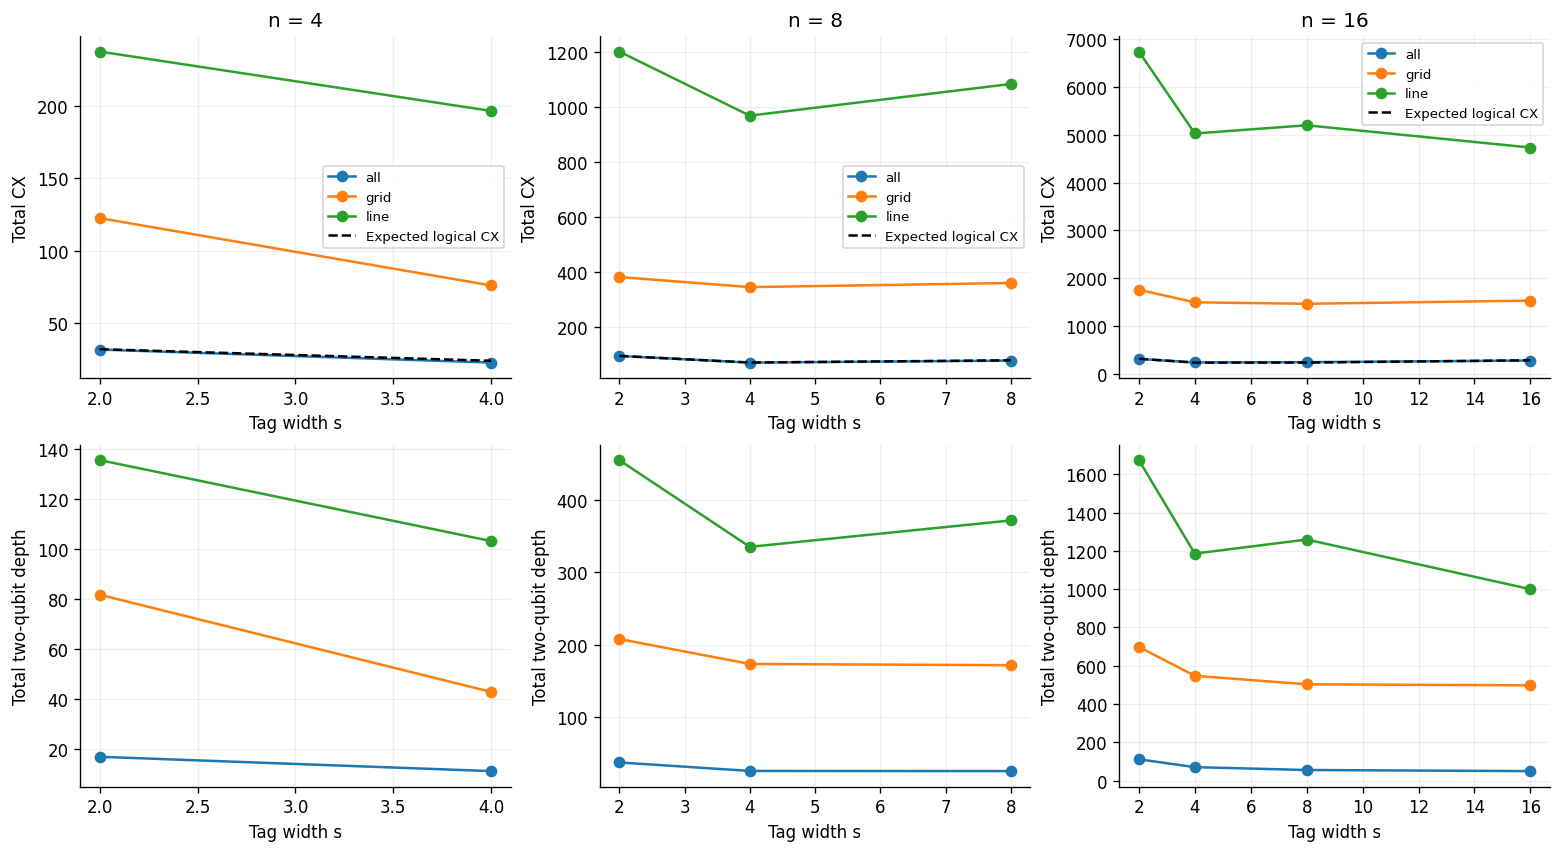

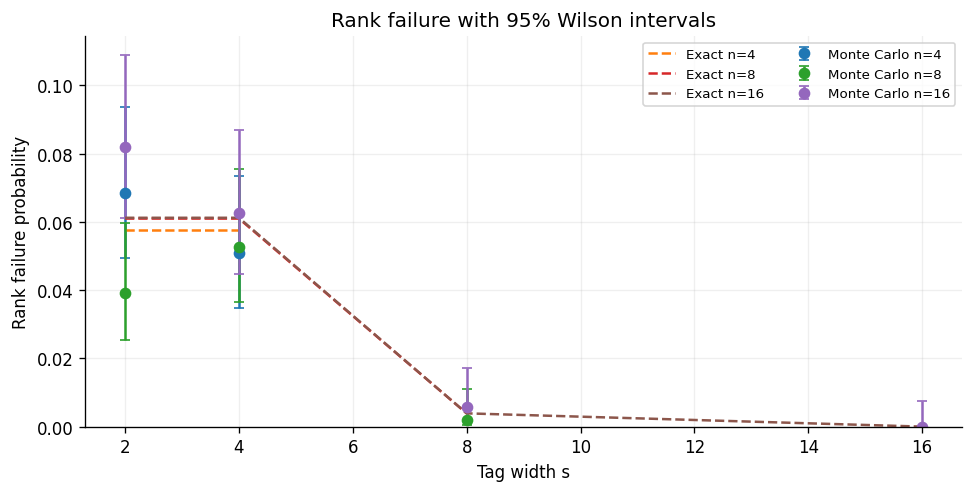

In [7]:
ns = sorted(resource_summary.n.unique())
fig, axes = plt.subplots(2, len(ns), figsize=(4.3*len(ns), 7), squeeze=False)
for col, n_value in enumerate(ns):
    for topology, g in resource_summary[resource_summary.n == n_value].groupby("topology"):
        g = g.sort_values("s")
        axes[0, col].plot(g.s, g.compiled_cx, "o-", label=topology)
        axes[1, col].plot(g.s, g.compiled_2q_depth, "o-", label=topology)
    logical = resource_summary[(resource_summary.n == n_value)
                               & (resource_summary.topology == CONFIG["resource"]["topologies"][0])]
    axes[0, col].plot(logical.s, logical.expected_cx, "k--", label="Expected logical CX")
    axes[0, col].set(title=f"n = {n_value}", ylabel="Total CX", xlabel="Tag width s")
    axes[1, col].set(ylabel="Total two-qubit depth", xlabel="Tag width s")
    axes[0, col].legend(fontsize=8)
save_figure(fig, "resource_tradeoffs")

fig, ax = plt.subplots(figsize=(8, 4))
for n_value, g in rank_results.groupby("n"):
    g = g.sort_values("s")
    ax.errorbar(g.s, g.failure,
                yerr=np.array([np.maximum(0, g.failure-g.ci_low),
                               np.maximum(0, g.ci_high-g.failure)]),
                fmt="o", capsize=3, label=f"Monte Carlo n={n_value}")
    ax.plot(g.s, g.exact, "--", label=f"Exact n={n_value}")
ax.set(xlabel="Tag width s", ylabel="Rank failure probability",
       title=f"Rank failure with {CONFIG['confidence']:.0%} Wilson intervals", ylim=(0, None))
ax.legend(fontsize=8, ncol=2)
save_figure(fig, "rank_failure")

**Interpretation:** identify configurations that reduce total cost while fitting
the qubit budget. Minimum CX count need not coincide with minimum depth. Rounding
the block count causes genuine discontinuities. Standard deviations in the table
describe variation across keys, not an individual circuit's uncertainty; small
key samples give exploratory routing estimates.

The exact rank curve is the reference. Binomial intervals quantify sampling
uncertainty. Do not resample singular keys until they become full-rank: that
changes the paper's key distribution. Zero observed failures still gives a
positive confidence upper bound.

## 4. Experiment 3 — Reliability under noise

**Question:** does the decoder still recover the entire input correctly, and
which noise components dominate?

Apply Model B with `ideal`, `gates`, `readout` and `combined` conditions at the
configured scales. Keys and inputs are matched across conditions. Each raw row
is a challenge with independent matrices across its $\nu$ blocks and **shots=1**
for each block. Experimental conditions are not concatenated into an adversary's
transcript. No postselection on full-rank keys is used.

Three outcomes are counted separately:
1. `correct`: the entire input is recovered exactly;
2. `failure`: rank deficiency or inconsistency, with no returned input;
3. `wrong`: a unique solution is returned but differs from the input.

The noise composition comes from the 2026 `simple_noise_model`. Its original
single-qubit gate list `u1,u2,u3,rx,ry,rz` is adapted to `h,x,s,sdg,z`; otherwise
the linear-tag Hadamards would escape the intended noise. See `THIRD_PARTY.md`.
We do not use the old five-qubit FakeVigoV2 calibration as a larger device model.

The readout identity in Model B explains why a system-bit error can contaminate
several equations. More equations do not by themselves correct these errors.
The ideal security theorem is not automatically extended to the noisy device.

In [8]:
noise_raw = noise_experiment(
    **CONFIG["noise"], **CONFIG["noise_base"], seed=CONFIG["seed"]+100,
    optimization_level=CONFIG["optimization_level"],
)
noise_results = noise_summary(noise_raw, CONFIG["confidence"])
ideal_rows = noise_raw[noise_raw["mode"] == "ideal"]
assert (ideal_rows[ideal_rows["rank"] == ideal_rows.n].outcome == "correct").all()
assert (ideal_rows[ideal_rows["rank"] < ideal_rows.n].outcome == "failure").all()
save_table(noise_raw, "noise_raw")
save_table(noise_results, "noise_summary")
display(noise_results)

,n,s,nu,topology,mode,scale,trials,correct,correct_low,correct_high,failure,failure_low,failure_high,wrong,wrong_low,wrong_high,full_rank_trials,correct_given_full_rank
0,6,2,4,all,ideal,0.0,32,0.75000,0.57893,0.86748,0.25000,0.13252,0.42107,0.00000,0.00000,0.10718,24,1.00000
1,6,2,4,all,combined,1.0,32,0.43750,0.28165,0.60674,0.40625,0.25520,0.57740,0.15625,0.06864,0.31754,24,0.58333
2,6,2,4,all,combined,2.0,32,0.12500,0.04970,0.28068,0.65625,0.48311,0.79590,0.21875,0.11024,0.38755,24,0.16667
3,6,2,4,all,gates,1.0,32,0.65625,0.48311,0.79590,0.34375,0.20410,0.51689,0.00000,0.00000,0.10718,24,0.87500
4,6,2,4,all,gates,2.0,32,0.50000,0.33631,0.66369,0.40625,0.25520,0.57740,0.09375,0.03240,0.24218,24,0.66667
5,6,2,4,all,readout,1.0,32,0.53125,0.36450,0.69131,0.43750,0.28165,0.60674,0.03125,0.00554,0.15744,24,0.70833
6,6,2,4,all,readout,2.0,32,0.21875,0.11024,0.38755,0.68750,0.51433,0.82047,0.09375,0.03240,0.24218,24,0.29167
7,6,2,4,line,ideal,0.0,32,0.75000,0.57893,0.86748,0.25000,0.13252,0.42107,0.00000,0.00000,0.10718,24,1.00000
8,6,2,4,line,combined,1.0,32,0.15625,0.06864,0.31754,0.62500,0.45254,0.77066,0.21875,0.11024,0.38755,24,0.20833
9,6,2,4,line,combined,2.0,32,0.03125,0.00554,0.15744,0.78125,0.61245,0.88976,0.18750,0.08890,0.35309,24,0.04167


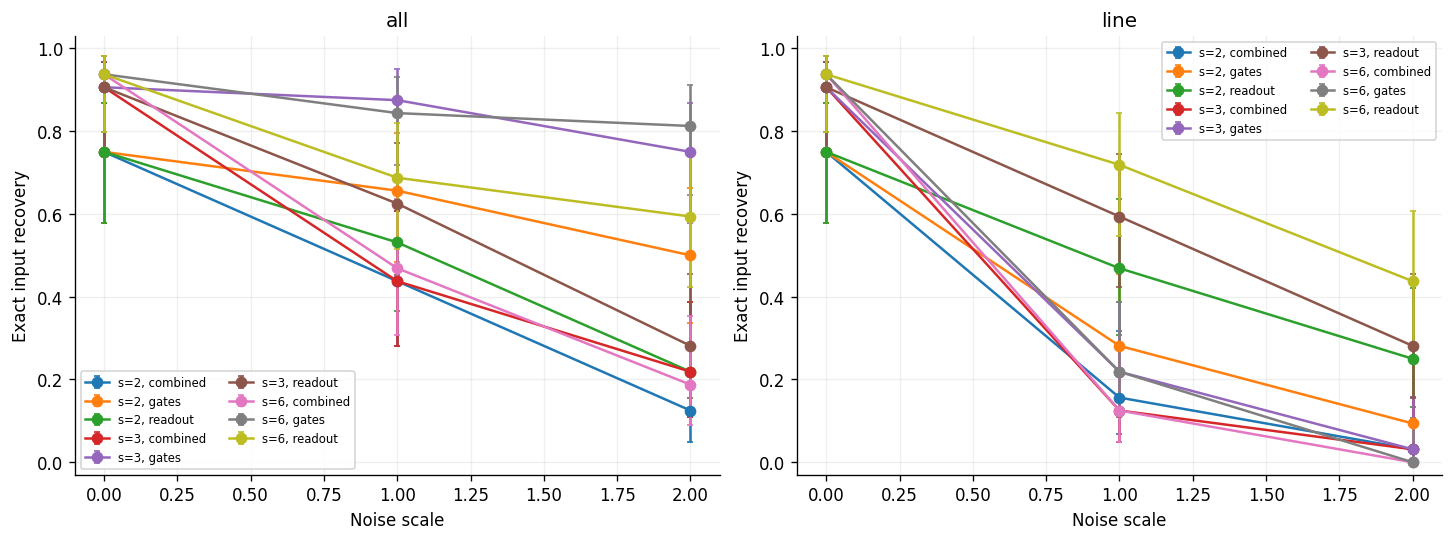

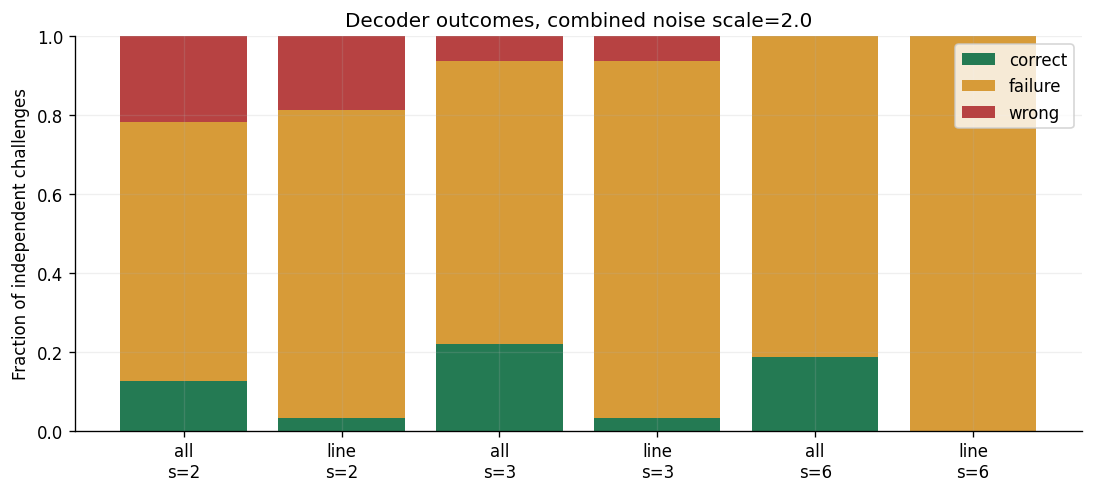

In [9]:
tops = CONFIG["noise"]["topologies"]
fig, axes = plt.subplots(1, len(tops), figsize=(6*len(tops), 4.4), squeeze=False)
for ax, topology in zip(axes[0], tops):
    for s_value in CONFIG["noise"]["tag_widths"]:
        g = noise_results[(noise_results.topology == topology)
                          & (noise_results.s == s_value)]
        ideal = g[g["mode"] == "ideal"]
        for mode in CONFIG["noise"]["modes"]:
            curve = pd.concat([ideal, g[g["mode"] == mode]]).sort_values("scale")
            ax.errorbar(curve.scale, curve.correct,
                        yerr=np.array([np.maximum(0, curve.correct-curve.correct_low),
                                       np.maximum(0, curve.correct_high-curve.correct)]),
                        marker="o", capsize=2, label=f"s={s_value}, {mode}")
    ax.set(title=topology, xlabel="Noise scale", ylabel="Exact input recovery",
           ylim=(-.03, 1.03))
    ax.legend(fontsize=7, ncol=2)
save_figure(fig, "noise_recovery")

# Keep all three decoding outcomes visible even when success is low.
selected = noise_results[(noise_results["mode"] == "combined")
                         & (noise_results.scale == max(CONFIG["noise"]["scales"]))]
if len(selected):
    labels = [f"{r.topology}\ns={r.s}" for r in selected.itertuples()]
    fig, ax = plt.subplots(figsize=(9, 4))
    bottom = np.zeros(len(selected))
    for outcome, color in [("correct", "#247a53"), ("failure", "#d79b38"), ("wrong", "#b74242")]:
        ax.bar(labels, selected[outcome], bottom=bottom, label=outcome, color=color)
        bottom += selected[outcome].to_numpy()
    ax.set(ylabel="Fraction of independent challenges", ylim=(0, 1),
           title=f"Decoder outcomes, combined noise scale={max(CONFIG['noise']['scales'])}")
    ax.legend()
    save_figure(fig, "noise_outcomes")

**Interpretation:** ideal success may be below one because randomly generated keys
can be rank-deficient. `correct_given_full_rank` separates that effect without
discarding it from the main metric. `wrong` represents undetected decoding errors
and must not be counted as success.

Wilson intervals use independent challenges, not individual bits or blocks.
With 32 challenges, intervals are wide: increase repetitions before comparing
small differences. Intervals are pointwise, not simultaneous over the whole grid.
Conditions share keys and therefore are not independent samples for an unpaired
comparison. Synthetic noise does not directly predict a real processor.

## 5. Experiment 4 — Collisions, phases and dephasing

**Hypothesis:** relative phases can change measured probabilities only when
multiple labels produce the same system output.

Use Model C's public `disjoint` and `overlap` permutation families, including
the rotation qubit. Sweep relative phase and index dephasing, and compare each
exact distribution with the fully dephased control. Record mean and maximum
total variation over inputs and optimal recovery for a uniform input prior.

These probabilities are computed exactly with density matrices, so no finite-shot
error bars apply. The attacker here knows the small public permutation family,
weights and phases. This is not the secret-matrix linear-tag adversary.

tv_max_over_phase  pguess_min  pguess_max
family   dephase                                           
disjoint 0.0            8.32667e-17        0.50        0.50
         0.5            5.55112e-17        0.50        0.50
         1.0            0.00000e+00        0.50        0.50
overlap  0.0            5.00000e-01        0.75        0.75
         0.5            2.50000e-01        0.75        0.75
         1.0            0.00000e+00        0.75        0.75

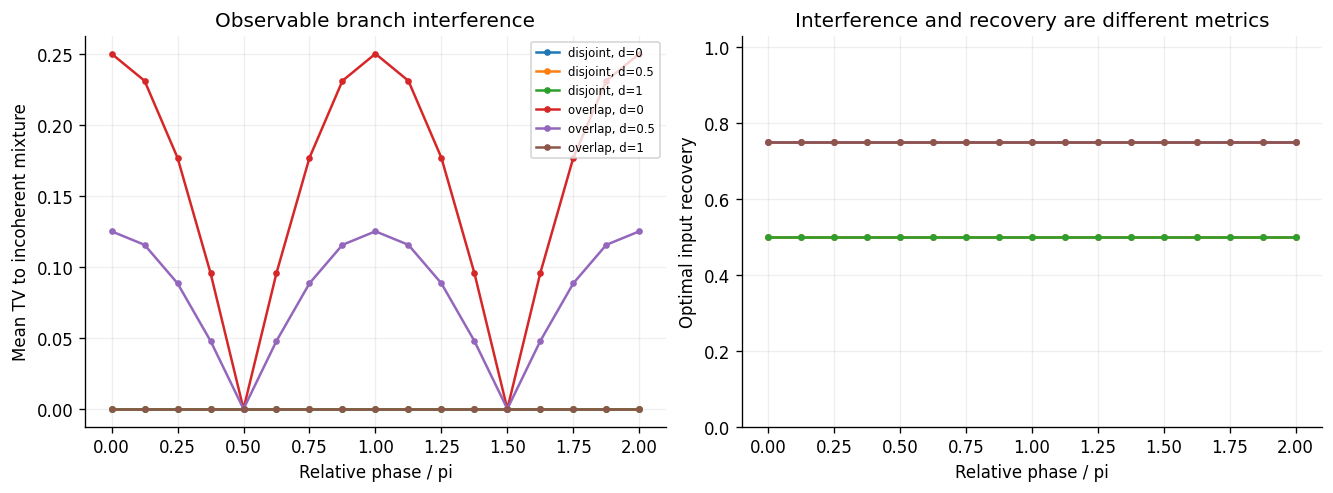

In [10]:
interference_results, interference_channels = interference_experiment(**CONFIG["interference"])
save_table(interference_results, "interference_summary")
save_table(interference_channels, "interference_channels")
assert interference_results.loc[interference_results.family == "disjoint", "tv_max"].max() < 1e-12
display(interference_results.groupby(["family", "dephase"]).agg(
    tv_max_over_phase=("tv_max", "max"),
    pguess_min=("pguess", "min"), pguess_max=("pguess", "max"),
))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for (family, dephase), g in interference_results.groupby(["family", "dephase"]):
    g = g.sort_values("phase")
    label = f"{family}, d={dephase:g}"
    axes[0].plot(g.phase/np.pi, g.tv_mean, "o-", markersize=3, label=label)
    axes[1].plot(g.phase/np.pi, g.pguess, "o-", markersize=3, label=label)
axes[0].set(xlabel="Relative phase / pi", ylabel="Mean TV to incoherent mixture",
            title="Observable branch interference")
axes[1].set(xlabel="Relative phase / pi", ylabel="Optimal input recovery",
            title="Interference and recovery are different metrics", ylim=(0, 1.03))
axes[0].legend(fontsize=7)
save_figure(fig, "interference")

**Interpretation:** all disjoint-family distances must vanish to numerical
precision. Overlapping fibers may give positive distances; overlap is necessary,
not sufficient for every choice of phases and weights.

With default weights $(1,1)$, optimal recovery is $1/2$ for the disjoint family
and $3/4$ for the overlap family, independently of phase. In the latter, half the
inputs are perfectly identifiable and half have two candidates. Flat recovery
curves are therefore informative: **observable interference is not equivalent
to improved security**. This small experiment does not establish classical
sampling hardness.

## 6. Experiment 5 — Reusing a matrix on the same input

**Changed threat model:** repeat each block $q$ times with the same unknown input
and the same matrix. The ciphertext-only attacker in Model D receives only the
transcripts and solves $D_YB_j^\top=D_R$ when the coefficient rank reaches $n$.
It then attempts to decode the input using the recovered matrices.

The `fresh` control regenerates each matrix at every execution. A fit accepted
on fresh data is not proof of key recovery; we still check whether its returned
input is correct. We measure this particular algorithm's success, not the
maximum success of every adversary.

The exact classical sampler is used here, following its validation against
the quantum circuit. The experiment is noiseless and assumes a common input.
Gaussian elimination is not assumed to recover matrices from noisy observations.

Differences in $Y$ form independent uniform rows. Under the reused policy:
$$P(\text{all keys identified})=(1-\epsilon_{\rm rank}(n,q-1))^\nu,$$
$$P(\text{input recovered by this attack})
=(1-\epsilon_{\rm rank}(n,q-1))^\nu
(1-\epsilon_{\rm rank}(n,\nu s)).$$
The last factor accounts for a rank-deficient stacked key matrix.
At least $q=n+1$ observations per block are needed by this identification criterion.

,policy,repetitions,trials,correct,ci_low,ci_high,fit_accepted,input_returned,keys_exact,theory_attack_success
0,fresh,1,256,0.00000,0.00000,0.01478,0.00000,0.00000,NaN,NaN
1,fresh,4,256,0.00000,0.00000,0.01478,0.00000,0.00000,NaN,NaN
2,fresh,8,256,0.00000,0.00000,0.01478,0.00000,0.00000,NaN,NaN
3,fresh,9,256,0.00000,0.00000,0.01478,0.00000,0.00000,NaN,NaN
4,fresh,12,256,0.00000,0.00000,0.01478,0.00000,0.00000,NaN,NaN
5,fresh,16,256,0.00000,0.00000,0.01478,0.00000,0.00000,NaN,NaN
6,fresh,24,256,0.00000,0.00000,0.01478,0.00000,0.00000,NaN,NaN
7,reused,1,256,0.00000,0.00000,0.01478,0.00000,0.00000,0.00000,0.00000
8,reused,4,256,0.00000,0.00000,0.01478,0.00000,0.00000,0.00000,0.00000
9,reused,8,256,0.00000,0.00000,0.01478,0.00000,0.00000,0.00000,0.00000


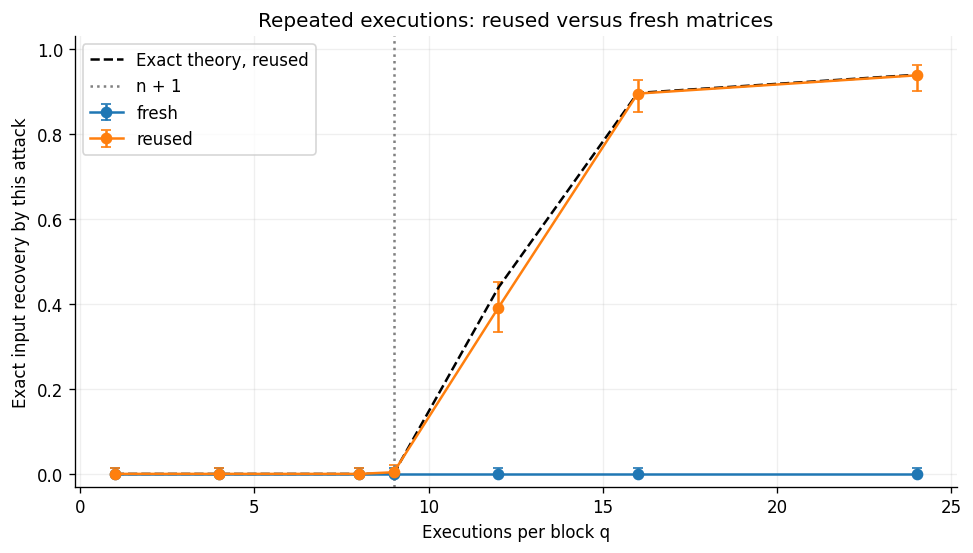

In [11]:
reuse_raw = reuse_experiment(**CONFIG["reuse"], seed=CONFIG["seed"]+200)
reuse_rows = []
for (policy, q), g in reuse_raw.groupby(["policy", "repetitions"]):
    successes = int(g.correct.sum())
    lo, hi = wilson(successes, len(g), CONFIG["confidence"])
    spec = CONFIG["reuse"]
    expected = (
        (1-rank_failure_exact(spec["n"], q-1))**spec["nu"]
        * (1-rank_failure_exact(spec["n"], spec["nu"]*spec["s"]))
        if policy == "reused" else np.nan
    )
    reuse_rows.append({
        "policy": policy, "repetitions": q, "trials": len(g),
        "correct": successes/len(g), "ci_low": lo, "ci_high": hi,
        "fit_accepted": g.accepted.mean(), "input_returned": g.returned.mean(),
        "keys_exact": g.keys_exact.mean() if policy == "reused" else np.nan,
        "theory_attack_success": expected,
    })
reuse_results = pd.DataFrame(reuse_rows)
save_table(reuse_raw, "reuse_raw")
save_table(reuse_results, "reuse_summary")
display(reuse_results)

fig, ax = plt.subplots(figsize=(8, 4.5))
for policy, g in reuse_results.groupby("policy"):
    g = g.sort_values("repetitions")
    ax.errorbar(g.repetitions, g.correct,
                yerr=np.array([np.maximum(0, g.correct-g.ci_low),
                               np.maximum(0, g.ci_high-g.correct)]),
                fmt="o-", capsize=3, label=policy)
g = reuse_results[reuse_results.policy == "reused"].sort_values("repetitions")
ax.plot(g.repetitions, g.theory_attack_success, "k--", label="Exact theory, reused")
ax.axvline(CONFIG["reuse"]["n"]+1, color="gray", linestyle=":", label="n + 1")
ax.set(xlabel="Executions per block q", ylabel="Exact input recovery by this attack",
       title="Repeated executions: reused versus fresh matrices", ylim=(-.03, 1.03))
ax.legend()
save_figure(fig, "key_reuse")

**Interpretation:** reused-key success should approach the limit determined by
the rank of $A$ as repetitions increase. Monte Carlo estimates need not equal
the exact curve. Points share transcript prefixes; confidence intervals are
pointwise. Low success for this attack on the fresh control does not establish
security against every attacker.

This experiment does not cover different messages under the same key: canceling
$x$ requires a common input. It describes a boundary of the paper's model,
without contradicting its fresh-key theorem.

## 7. Outputs, reproducibility and scope

Each execution writes a new directory in `results/` containing the complete
configuration, seeds, software versions, raw and summary CSV tables, PNG/PDF
figures and analytic/circuit agreement checks.

Run `python start.py --check` to check dependencies and execute the tests.
They independently check binary algebra by exhaustive enumeration, rank
probabilities, the linear-tag distribution, routing, actual noise attachment,
the Born formula for both permutation families, the reuse attack and ZIP contents.
Run `python start.py --run` to execute and save the whole notebook without opening
Jupyter. Double-click `start.cmd` on Windows to set up and open JupyterLab.

For publication, distinguish logical resources, compiled circuit costs, synthetic
noise simulations and physical measurements. No real QPU or current device
calibration is used. Clifford simulation does not imply quantum advantage.
The exact classical sampler is an essential control.

References:

1. Local paper draft: *Keyed Linear-Tag Construction* and *Inversion Security*.
2. ISCAS 2026 `utilities/noise_level_and_topology.py` and `config.py`;
   attribution and original license are retained in `THIRD_PARTY.md`.
3. [Qiskit Aer simulator and stabilizer documentation](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.AerSimulator.html).
4. [Daskin, all-outcomes LCU, arXiv:2605.02986v2](https://arxiv.org/abs/2605.02986v2).

In [12]:
print("Campaign completed:", RUN_DIR)
print("Exported files:")
for path in sorted(RUN_DIR.iterdir()):
    print(" ", path.name)

Campaign completed: C:\Users\marco\Desktop\Università\quantum\iscas2027_quantum_crypto\iscas2027_experiments\results\20261020T140200_568104Z
Exported files:
  config.json
  interference.pdf
  interference.png
  interference_channels.csv
  interference_summary.csv
  key_reuse.pdf
  key_reuse.png
  linear_tag_checks.csv
  linear_tag_distribution.csv
  linear_tag_distribution.pdf
  linear_tag_distribution.png
  noise_outcomes.pdf
  noise_outcomes.png
  noise_raw.csv
  noise_recovery.pdf
  noise_recovery.png
  noise_summary.csv
  rank_failure.csv
  rank_failure.pdf
  rank_failure.png
  resource_raw.csv
  resource_summary.csv
  resource_tradeoffs.pdf
  resource_tradeoffs.png
  reuse_raw.csv
  reuse_summary.csv
